<a href="https://colab.research.google.com/github/saran6ya/Smart_Malnutrition_Detection_System/blob/main/SmartMalnutrition_Image_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## File Extraction

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Malnutrition Detection.v1i.yolov11.zip to Malnutrition Detection.v1i.yolov11.zip


### Extract the uploaded zip file
This cell extracts the content of the `Malnutrition Detection.v1i.yolov11.zip` file to the `/content/malnutrition_dataset` directory.

In [ ]:
# unzip the file
import zipfile
import os

zip_path = "/content/Malnutrition Detection.v1i.yolov11.zip"
extract_path = "/content/malnutrition_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


### Display the content of `data.yaml`
This cell reads and prints the content of the `data.yaml` file, which typically contains dataset configuration like train/validation/test paths, class names, and Roboflow details.

In [ ]:
# checking what are the folders exist inside our zipped file
print(open("/content/malnutrition_dataset/data.yaml").read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Healthy', 'Malnourished']

roboflow:
  workspace: malnutrition-se2ki
  project: malnutrition-detection-b0uqc-oz84m
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/malnutrition-se2ki/malnutrition-detection-b0uqc-oz84m/dataset/1


### Initial Check of Dataset Splits
This cell attempts to iterate through 'train', 'valid', and 'test' splits to count images and labels. It failed because the 'test' directory did not exist initially in the extracted dataset.

In [ ]:
import os

base_path = "/content/malnutrition_dataset"

for split in ["train", "valid", "test"]:

    image_path = os.path.join(base_path, split, "images")
    label_path = os.path.join(base_path, split, "labels")

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_path)
        if f.endswith(".txt")
    ]

    print(split)
    print("Images :", len(images))
    print("Labels :", len(labels))
    print()

train
Images : 194
Labels : 194

valid
Images : 48
Labels : 48



FileNotFoundError: [Errno 2] No such file or directory: '/content/malnutrition_dataset/test/images'

### Split Training Data into New Train and Test Sets
This cell addresses the missing 'test' split by randomly selecting 20% of the original training images and their corresponding labels to create a new 'test' set. The remaining 80% stay in the 'train' set. It uses `shutil.move` to relocate these files.

## Since our dataset is not having test folder so we are splitting our training dataset folder into two for 80% for training and 20% for testing

In [ ]:
import os
import random
import shutil

base_path = "/content/malnutrition_dataset"

train_images = os.path.join(base_path, "train", "images")
train_labels = os.path.join(base_path, "train", "labels")

test_images = os.path.join(base_path, "test", "images")
test_labels = os.path.join(base_path, "test", "labels")

# Create test folders
os.makedirs(test_images, exist_ok=True)
os.makedirs(test_labels, exist_ok=True)

# Get all images
images = [
    f for f in os.listdir(train_images)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Randomly select 20% for testing
random.seed(42)
random.shuffle(images)

test_count = int(len(images) * 0.20)
test_files = images[:test_count]

# Move images and matching labels
moved = 0

for image_file in test_files:
    image_src = os.path.join(train_images, image_file)
    image_dst = os.path.join(test_images, image_file)

    label_file = os.path.splitext(image_file)[0] + ".txt"
    label_src = os.path.join(train_labels, label_file)
    label_dst = os.path.join(test_labels, label_file)

    if os.path.exists(label_src):
        shutil.move(image_src, image_dst)
        shutil.move(label_src, label_dst)
        moved += 1

print("Test images created:", moved)
print("Train images:", len(os.listdir(train_images)))
print("Validation images:", len(os.listdir(os.path.join(base_path, "valid", "images"))))

Test images created: 38
Train images: 156
Validation images: 48


### Display Dataset Directory Structure
This cell uses `os.walk` to recursively list the directory structure of the `/content/malnutrition_dataset` folder, showing the hierarchy of subdirectories like 'test', 'valid', and 'train', along with some sample files.

In [ ]:
import os

base_path = "/content/malnutrition_dataset"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level < 2:
        for file in files[:5]:
            print(f"{indent}  {file}")

malnutrition_dataset/
  README.roboflow.txt
  data.yaml
  README.dataset.txt
  train/
    labels/
    images/
  test/
    labels/
    images/
  valid/
    labels/
    images/


### Verify Dataset Directory Structure
This cell uses `os.walk` to recursively print all directories within `/content/malnutrition_dataset`, confirming the presence of the newly created 'test' directory along with 'train' and 'valid' splits.

## Now we can see our dataset contains test folder

In [ ]:
import os

for root, dirs, files in os.walk("/content/malnutrition_dataset"):
    print(root)

/content/malnutrition_dataset
/content/malnutrition_dataset/train
/content/malnutrition_dataset/train/labels
/content/malnutrition_dataset/train/images
/content/malnutrition_dataset/test
/content/malnutrition_dataset/test/labels
/content/malnutrition_dataset/test/images
/content/malnutrition_dataset/valid
/content/malnutrition_dataset/valid/labels
/content/malnutrition_dataset/valid/images


### Count Images and Labels per Split (After Resplitting)
This cell re-checks the number of images and labels in each of the 'train', 'valid', and 'test' splits after the previous step created a new 'test' set from the original 'train' data.

## Checking how many labels and images in each folder

In [ ]:
import os

dataset_path = "/content/malnutrition_dataset"

for split in ["train", "valid", "test"]:

    image_path = os.path.join(base_path, split, "images")
    label_path = os.path.join(base_path, split, "labels")

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_path)
        if f.endswith(".txt")
    ]

    print(split)
    print("Images :", len(images))
    print("Labels :", len(labels))
    print()

train
Images : 156
Labels : 156

valid
Images : 48
Labels : 48

test
Images : 38
Labels : 38



### Check for Corrupted or Small Images
This cell iterates through the images in each split ('train', 'valid', 'test') to identify any corrupted image files or images with dimensions smaller than 100x100 pixels, using the Pillow library.

In [ ]:
from PIL import Image
import os

dataset_path = "/content/malnutrition_dataset"

for split in ["train", "valid", "test"]:

    image_path = os.path.join(dataset_path, split, "images")

    bad_images = []
    small_images = []

    for filename in os.listdir(image_path):

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        filepath = os.path.join(image_path, filename)

        try:
            with Image.open(filepath) as img:

                width, height = img.size

                if width < 100 or height < 100:
                    small_images.append(
                        (filename, width, height)
                    )

        except Exception as e:
            bad_images.append(
                (filename, str(e))
            )

    print("\n", split.upper())
    print("Small images :", len(small_images))
    print("Corrupted images :", len(bad_images))

    if small_images:
        print("Small images:", small_images[:5])

    if bad_images:
        print("Corrupted images:", bad_images[:5])


 TRAIN
Small images : 0
Corrupted images : 0

 VALID
Small images : 0
Corrupted images : 0

 TEST
Small images : 0
Corrupted images : 0


### Display Sample Training Images
This cell randomly selects and displays 9 images from the training set to visually inspect the dataset. It uses `matplotlib` for plotting and `Pillow` for image loading.

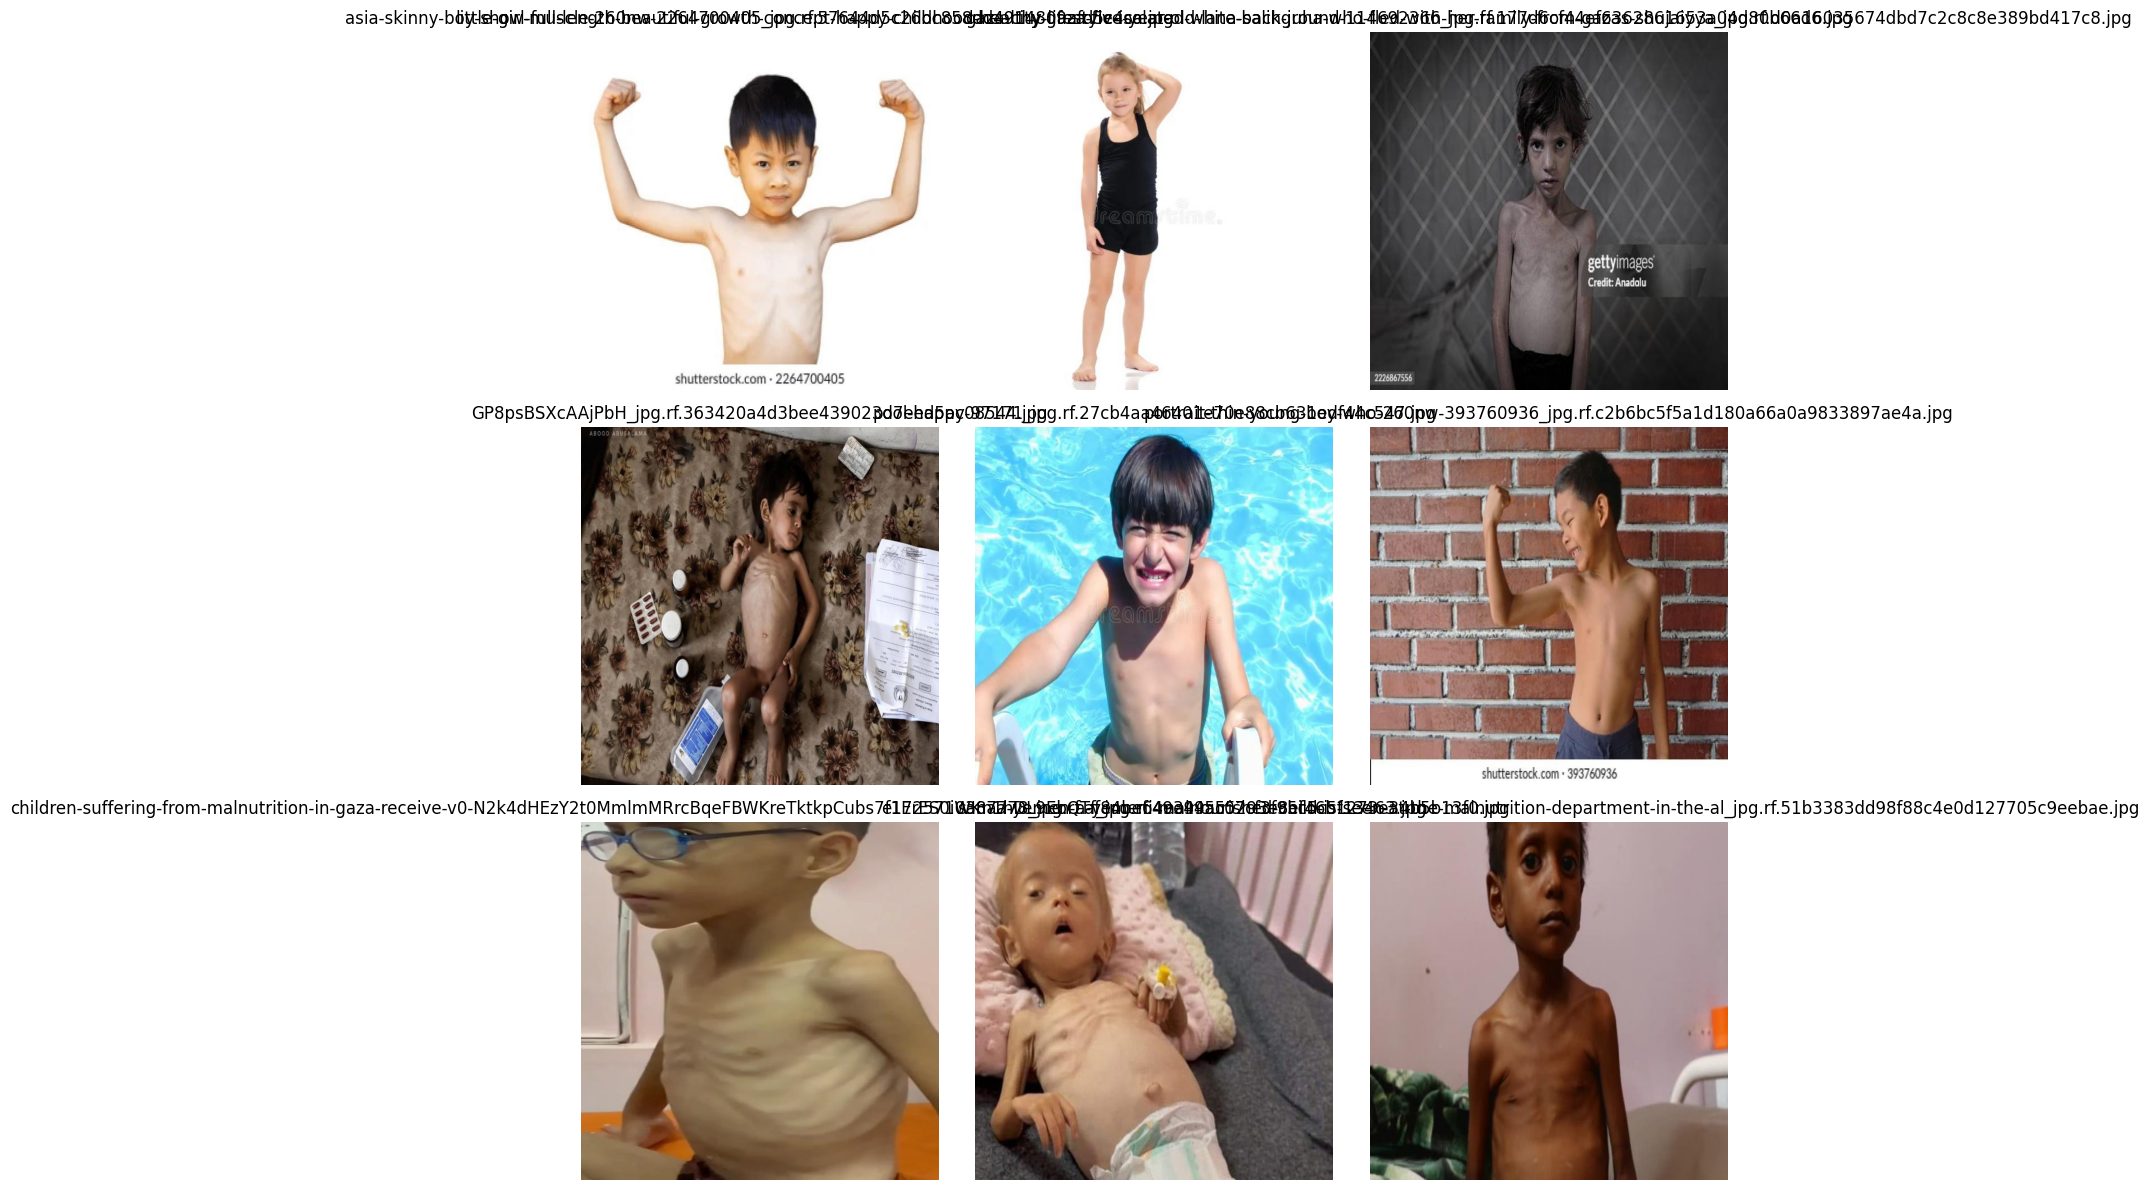

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

dataset_path = "/content/malnutrition_dataset"

image_path = os.path.join(dataset_path, "train", "images")

images = [
    f for f in os.listdir(image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Select 9 random images
sample_images = random.sample(images, min(9, len(images)))

plt.figure(figsize=(12, 12))

for i, filename in enumerate(sample_images):

    filepath = os.path.join(image_path, filename)
    image = Image.open(filepath)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Analyze Class Distribution in Labels
This cell counts the occurrences of each class ID (0 for Healthy, 1 for Malnourished) across all label files within the 'train', 'valid', and 'test' splits, providing an overview of the dataset's class balance.

In [ ]:
import os
from collections import Counter

dataset_path = "/content/malnutrition_dataset"

for split in ["train", "valid", "test"]:

    label_path = os.path.join(dataset_path, split, "labels")

    class_counts = Counter()

    for filename in os.listdir(label_path):

        if not filename.endswith(".txt"):
            continue

        filepath = os.path.join(label_path, filename)

        with open(filepath, "r") as f:
            for line in f:
                line = line.strip()

                if line:
                    class_id = line.split()[0]
                    class_counts[class_id] += 1

    print(split.upper())
    print("Class distribution:", class_counts)
    print()

TRAIN
Class distribution: Counter({'0': 86, '1': 70})

VALID
Class distribution: Counter({'1': 24, '0': 24})

TEST
Class distribution: Counter({'1': 23, '0': 15})



### Display `data.yaml` Content
This cell reads and prints the content of the `data.yaml` file, which defines the dataset's structure and class information, to ensure it's correctly configured.

In [ ]:
import os

yaml_path = "/content/malnutrition_dataset/data.yaml"

if os.path.exists(yaml_path):
    with open(yaml_path, "r") as f:
        print(f.read())
else:
    print("data.yaml not found")

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Healthy', 'Malnourished']

roboflow:
  workspace: malnutrition-se2ki
  project: malnutrition-detection-b0uqc-oz84m
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/malnutrition-se2ki/malnutrition-detection-b0uqc-oz84m/dataset/1


### Visualize Bounding Boxes on Sample Images
This cell randomly selects 6 images from the training set and visualizes their corresponding YOLO bounding box annotations. It draws rectangles and class labels on the images to show the ground truth detections.

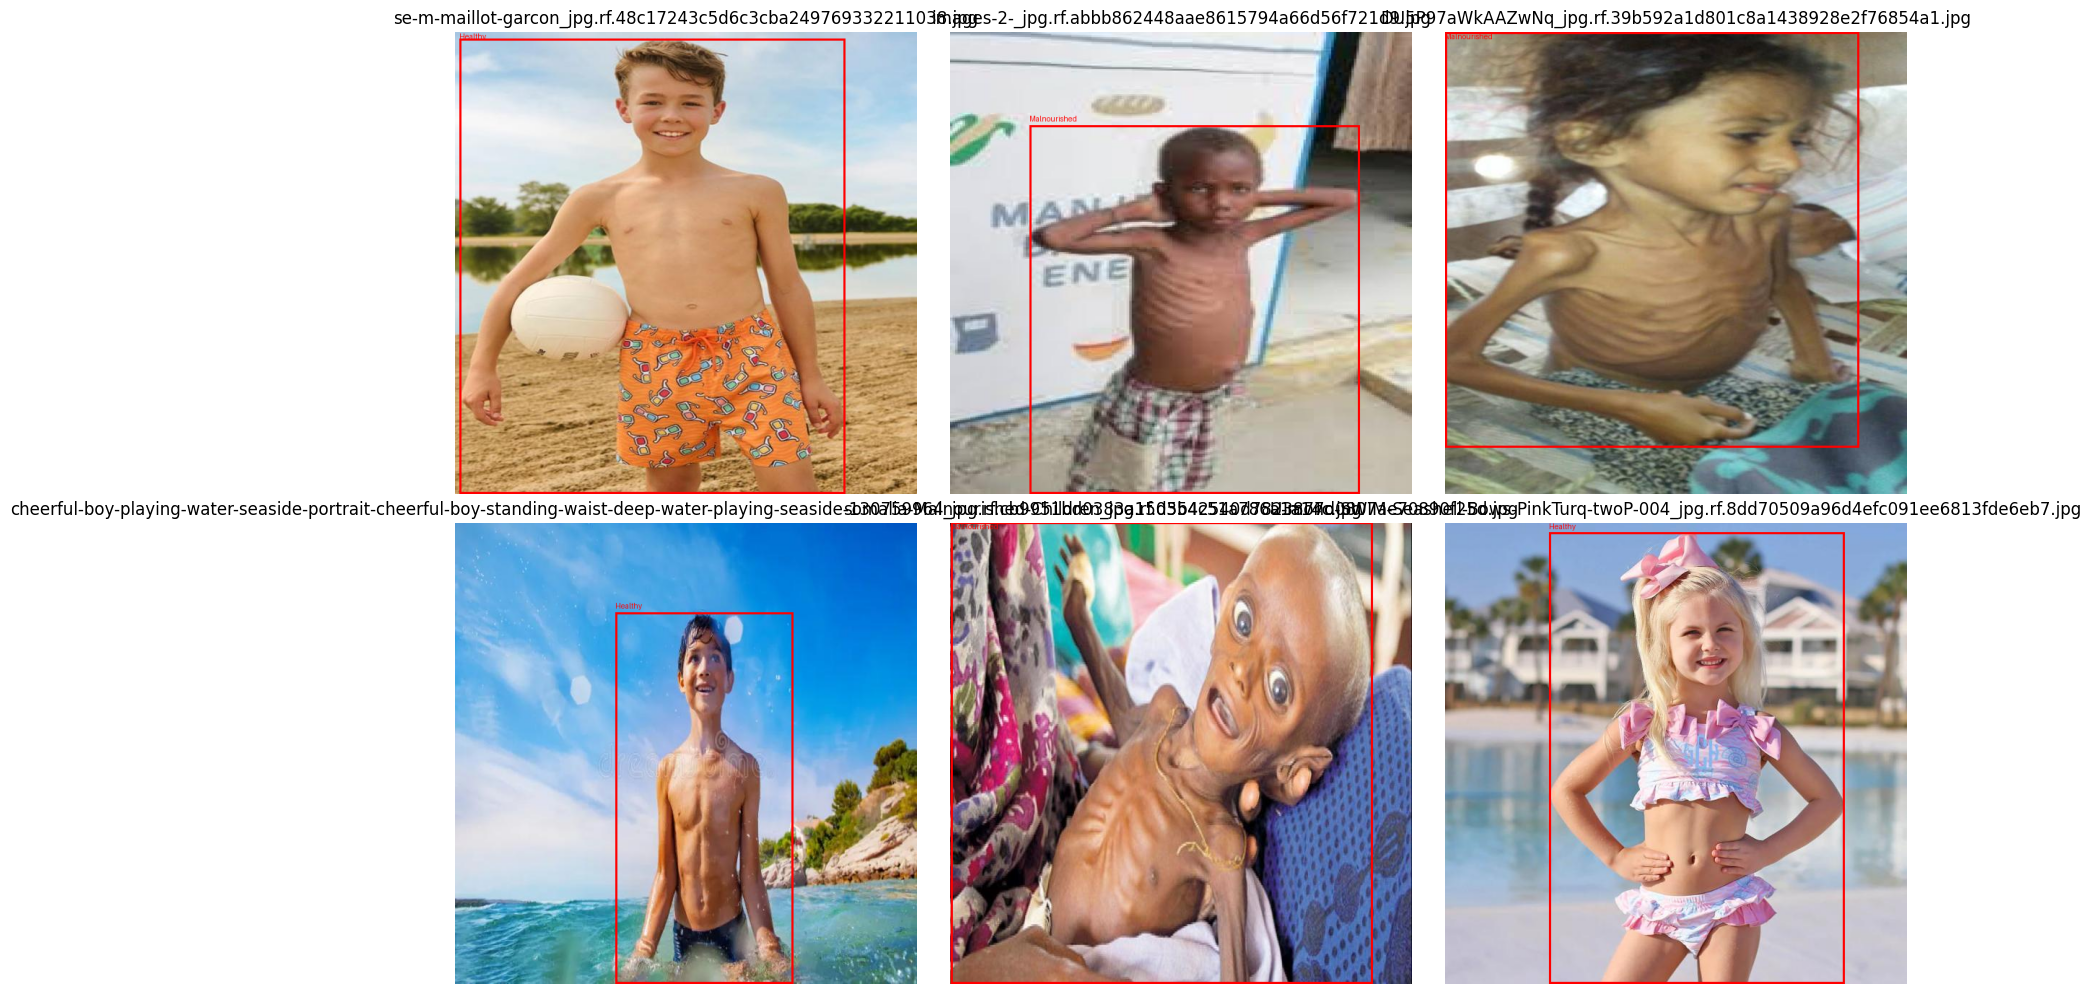

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

dataset_path = "/content/malnutrition_dataset"

class_names = {
    0: "Healthy",
    1: "Malnourished"
}

image_path = os.path.join(dataset_path, "train", "images")
label_path = os.path.join(dataset_path, "train", "labels")

images = [
    f for f in os.listdir(image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Select 6 random images
sample_images = random.sample(images, min(6, len(images)))

plt.figure(figsize=(15, 10))

for i, filename in enumerate(sample_images):

    img_file = os.path.join(image_path, filename)
    label_file = os.path.join(
        label_path,
        os.path.splitext(filename)[0] + ".txt"
    )

    image = Image.open(img_file).convert("RGB")

    draw = ImageDraw.Draw(image)

    width, height = image.size

    # Read YOLO labels
    if os.path.exists(label_file):

        with open(label_file, "r") as f:
            lines = f.readlines()

        for line in lines:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            x_center = float(parts[1]) * width
            y_center = float(parts[2]) * height
            box_width = float(parts[3]) * width
            box_height = float(parts[4]) * height

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            label = class_names.get(class_id, "Unknown")

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                label,
                fill="red"
            )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Validate Labels and Check Class Balance
This cell performs a detailed validation of label files for each split. It checks for missing labels, invalid label formats, and class IDs outside the defined range (0 or 1). It also provides a count of healthy and malnourished objects per split.

In [ ]:
import os
from collections import Counter

dataset_path = "/content/malnutrition_dataset"

class_names = {
    0: "Healthy",
    1: "Malnourished"
}

for split in ["train", "valid", "test"]:

    image_path = os.path.join(dataset_path, split, "images")
    label_path = os.path.join(dataset_path, split, "labels")

    class_counts = Counter()
    missing_labels = []
    invalid_labels = []

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image in images:

        label_file = os.path.join(
            label_path,
            os.path.splitext(image)[0] + ".txt"
        )

        if not os.path.exists(label_file):
            missing_labels.append(image)
            continue

        with open(label_file, "r") as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()

            if len(parts) != 5:
                invalid_labels.append(image)
                continue

            try:
                class_id = int(parts[0])

                if class_id not in class_names:
                    invalid_labels.append(image)
                else:
                    class_counts[class_id] += 1

            except:
                invalid_labels.append(image)

    print("=" * 40)
    print(split.upper())
    print("Total images:", len(images))

    for class_id, name in class_names.items():
        print(f"{name}: {class_counts[class_id]}")

    print("Missing labels:", len(missing_labels))
    print("Invalid labels:", len(invalid_labels))

TRAIN
Total images: 156
Healthy: 86
Malnourished: 70
Missing labels: 0
Invalid labels: 0
VALID
Total images: 48
Healthy: 24
Malnourished: 24
Missing labels: 0
Invalid labels: 0
TEST
Total images: 38
Healthy: 15
Malnourished: 23
Missing labels: 0
Invalid labels: 0


### Create a Class-Balanced Test Set
This cell preprocesses the training data to create a new, class-balanced test set. It separates healthy and malnourished images, then randomly samples an equal number from each class to form the new test split, ensuring balanced representation.

In [ ]:
import os
import random
import shutil

dataset_path = "/content/malnutrition_dataset"
processed_path = "/content/malnutrition_processed"

train_img = os.path.join(base_path, "train", "images")
train_lbl = os.path.join(base_path, "train", "labels")

# Read original training images by class
healthy = []
malnourished = []

for image in os.listdir(train_img):

    if not image.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    label_file = os.path.join(
        train_lbl,
        os.path.splitext(image)[0] + ".txt"
    )

    with open(label_file, "r") as f:
        lines = f.readlines()

    classes = [int(line.split()[0]) for line in lines if line.strip()]

    if 1 in classes:
        malnourished.append(image)
    else:
        healthy.append(image)

random.seed(42)

# Select equal number for test
test_count = min(len(healthy), len(malnourished), 38 // 2)

test_healthy = random.sample(healthy, test_count)
test_malnourished = random.sample(malnourished, test_count)

test_images = test_healthy + test_malnourished

print("Healthy available:", len(healthy))
print("Malnourished available:", len(malnourished))
print("Test Healthy:", len(test_healthy))
print("Test Malnourished:", len(test_malnourished))
print("Total Test:", len(test_images))

Healthy available: 86
Malnourished available: 70
Test Healthy: 19
Test Malnourished: 19
Total Test: 38


### Create New Dataset with Balanced Splits
This cell orchestrates the creation of a new dataset directory (`/content/malnutrition_processed_v2`) with properly balanced 'train', 'valid', and 'test' splits. It copies images and labels based on the balanced test set created previously and preserves the validation set.

In [ ]:
import os
import shutil

dataset_path = "/content/malnutrition_dataset"
new_path = "/content/malnutrition_processed_v2"

# Remove old version if it already exists
if os.path.exists(new_path):
    shutil.rmtree(new_path)

# Create folders
for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(new_path, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(new_path, split, "labels"), exist_ok=True)


# --------------------------------------------------
# 1. CREATE TEST SET
# --------------------------------------------------

train_img_path = os.path.join(base_path, "train", "images")
train_lbl_path = os.path.join(base_path, "train", "labels")

test_images = test_healthy + test_malnourished

for image in test_images:

    label = os.path.splitext(image)[0] + ".txt"

    shutil.copy(
        os.path.join(train_img_path, image),
        os.path.join(new_path, "test", "images", image)
    )

    shutil.copy(
        os.path.join(train_lbl_path, label),
        os.path.join(new_path, "test", "labels", label)
    )


# --------------------------------------------------
# 2. CREATE NEW TRAIN SET
# --------------------------------------------------

test_set = set(test_images)

for image in os.listdir(train_img_path):

    if not image.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    # Skip images already selected for test
    if image in test_set:
        continue

    label = os.path.splitext(image)[0] + ".txt"

    shutil.copy(
        os.path.join(train_img_path, image),
        os.path.join(new_path, "train", "images", image)
    )

    if os.path.exists(os.path.join(train_lbl_path, label)):
        shutil.copy(
            os.path.join(train_lbl_path, label),
            os.path.join(new_path, "train", "labels", label)
        )


# --------------------------------------------------
# 3. COPY VALIDATION SET
# --------------------------------------------------

valid_img_path = os.path.join(base_path, "valid", "images")
valid_lbl_path = os.path.join(base_path, "valid", "labels")

for image in os.listdir(valid_img_path):

    if not image.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    label = os.path.splitext(image)[0] + ".txt"

    shutil.copy(
        os.path.join(valid_img_path, image),
        os.path.join(new_path, "valid", "images", image)
    )

    if os.path.exists(os.path.join(valid_lbl_path, label)):
        shutil.copy(
            os.path.join(valid_lbl_path, label),
            os.path.join(new_path, "valid", "labels", label)
        )


print("✅ Corrected dataset created!")
print("Location:", new_path)

✅ Corrected dataset created!
Location: /content/malnutrition_processed_v2


### Verify Class Distribution in New Dataset
This cell checks the class distribution (Healthy vs. Malnourished) within the newly created 'train', 'valid', and 'test' splits of the `/content/malnutrition_processed_v2` dataset. It confirms the balanced class distribution for the test set.

In [ ]:
import os
from collections import Counter

new_path = "/content/malnutrition_processed_v2"

class_names = {
    0: "Healthy",
    1: "Malnourished"
}

for split in ["train", "valid", "test"]:

    image_path = os.path.join(dataset_path, split, "images")
    label_path = os.path.join(dataset_path, split, "labels")

    class_counts = Counter()

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image in images:

        label_file = os.path.join(
            label_path,
            os.path.splitext(image)[0] + ".txt"
        )

        with open(label_file, "r") as f:
            for line in f:

                if line.strip():
                    class_id = int(line.split()[0])
                    class_counts[class_id] += 1

    print("=" * 40)
    print(split.upper())
    print("Images:", len(images))
    print("Healthy:", class_counts[0])
    print("Malnourished:", class_counts[1])

TRAIN
Images: 156
Healthy: 86
Malnourished: 70
VALID
Images: 48
Healthy: 24
Malnourished: 24
TEST
Images: 38
Healthy: 15
Malnourished: 23


### Analyze Image Dimensions in New Dataset
This cell examines the dimensions (width, height) of all images within the 'train', 'valid', and 'test' splits of the new processed dataset. It reports the total number of images, unique dimensions, and the most common dimensions, which helps confirm uniformity.

In [ ]:
from PIL import Image
import os
from collections import Counter

new_path = "/content/malnutrition_processed_v2"

for split in ["train", "valid", "test"]:

    image_path = os.path.join(dataset_path, split, "images")

    dimensions = []

    for filename in os.listdir(image_path):

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        filepath = os.path.join(image_path, filename)

        try:
            with Image.open(filepath) as img:
                dimensions.append(img.size)

        except:
            pass

    dimension_counts = Counter(dimensions)

    print("=" * 40)
    print(split.upper())
    print("Total images:", len(dimensions))
    print("Unique dimensions:", len(dimension_counts))

    print("\nMost common dimensions:")
    for dimension, count in dimension_counts.most_common(10):
        print(dimension, "→", count)

TRAIN
Total images: 156
Unique dimensions: 1

Most common dimensions:
(640, 640) → 156
VALID
Total images: 48
Unique dimensions: 1

Most common dimensions:
(640, 640) → 48
TEST
Total images: 38
Unique dimensions: 1

Most common dimensions:
(640, 640) → 38


### Generate `data.yaml` for Processed Dataset
This cell creates a new `data.yaml` configuration file for the `/content/malnutrition_processed_v2` dataset. This YAML file specifies the paths for the train, validation, and test images, along with the number of classes and their names, essential for YOLO training.

In [ ]:
import os

new_path = "/content/malnutrition_processed_v2"

yaml_content = f"""
path: {dataset_path}
train: train/images
val: valid/images
test: test/images

nc: 2
names: ['Healthy', 'Malnourished']
"""

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content.strip())

print("✅ data.yaml created!")
print("\nContents:\n")
print(yaml_content)

✅ data.yaml created!

Contents:


path: /content/malnutrition_dataset
train: train/images
val: valid/images
test: test/images

nc: 2
names: ['Healthy', 'Malnourished']



### Validate Label File Format in New Dataset
This cell performs a rigorous check on the annotation files in the `malnutrition_processed_v2` dataset. It verifies that each label file has the correct format (5 parts: class_id, x_center, y_center, width, height), that class IDs are valid (0 or 1), and that bounding box coordinates are within the 0-1 range.

In [ ]:
import os

new_path = "/content/malnutrition_processed_v2"

for split in ["train", "valid", "test"]:

    label_path = os.path.join(dataset_path, split, "labels")

    invalid = []

    for filename in os.listdir(label_path):

        if not filename.endswith(".txt"):
            continue

        filepath = os.path.join(label_path, filename)

        with open(filepath, "r") as f:
            lines = f.readlines()

        for line_number, line in enumerate(lines, start=1):

            parts = line.strip().split()

            if len(parts) != 5:
                invalid.append((filename, line_number, "Wrong format"))
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                if class_id not in [0, 1]:
                    invalid.append((filename, line_number, "Invalid class"))

                if not all(0 <= value <= 1 for value in [x, y, w, h]):
                    invalid.append((filename, line_number, "Coordinates outside 0-1"))

            except:
                invalid.append((filename, line_number, "Non-numeric value"))

    print("=" * 40)
    print(split.upper())
    print("Invalid annotations:", len(invalid))

    if invalid:
        print(invalid[:5])

TRAIN
Invalid annotations: 0
VALID
Invalid annotations: 0
TEST
Invalid annotations: 0


### Summarize Object and Image Counts per Class
This cell provides a final summary of the object counts for 'Healthy' and 'Malnourished' classes across the 'train', 'valid', and 'test' splits of the processed dataset. It also reports how many images contain at least one instance of each class.

In [ ]:
import os
from collections import Counter

new_path = "/content/malnutrition_processed_v2"

for split in ["train", "valid", "test"]:

    label_path = os.path.join(new_path, split, "labels")

    class_counts = Counter()
    images_per_class = Counter()

    for filename in os.listdir(label_path):

        if not filename.endswith(".txt"):
            continue

        filepath = os.path.join(label_path, filename)

        classes_in_image = set()

        with open(filepath, "r") as f:
            for line in f:

                if line.strip():
                    class_id = int(line.split()[0])
                    class_counts[class_id] += 1
                    classes_in_image.add(class_id)

        for class_id in classes_in_image:
            images_per_class[class_id] += 1

    print("=" * 40)
    print(split.upper())

    print("Objects:")
    print("Healthy:", class_counts[0])
    print("Malnourished:", class_counts[1])

    print("\nImages containing each class:")
    print("Healthy:", images_per_class[0])
    print("Malnourished:", images_per_class[1])

TRAIN
Objects:
Healthy: 67
Malnourished: 51

Images containing each class:
Healthy: 67
Malnourished: 51
VALID
Objects:
Healthy: 24
Malnourished: 24

Images containing each class:
Healthy: 24
Malnourished: 24
TEST
Objects:
Healthy: 19
Malnourished: 19

Images containing each class:
Healthy: 19
Malnourished: 19


## Visualize Bounding Boxes : We must confirm that the YOLO labels are correctly pointing to the person/body in the image.

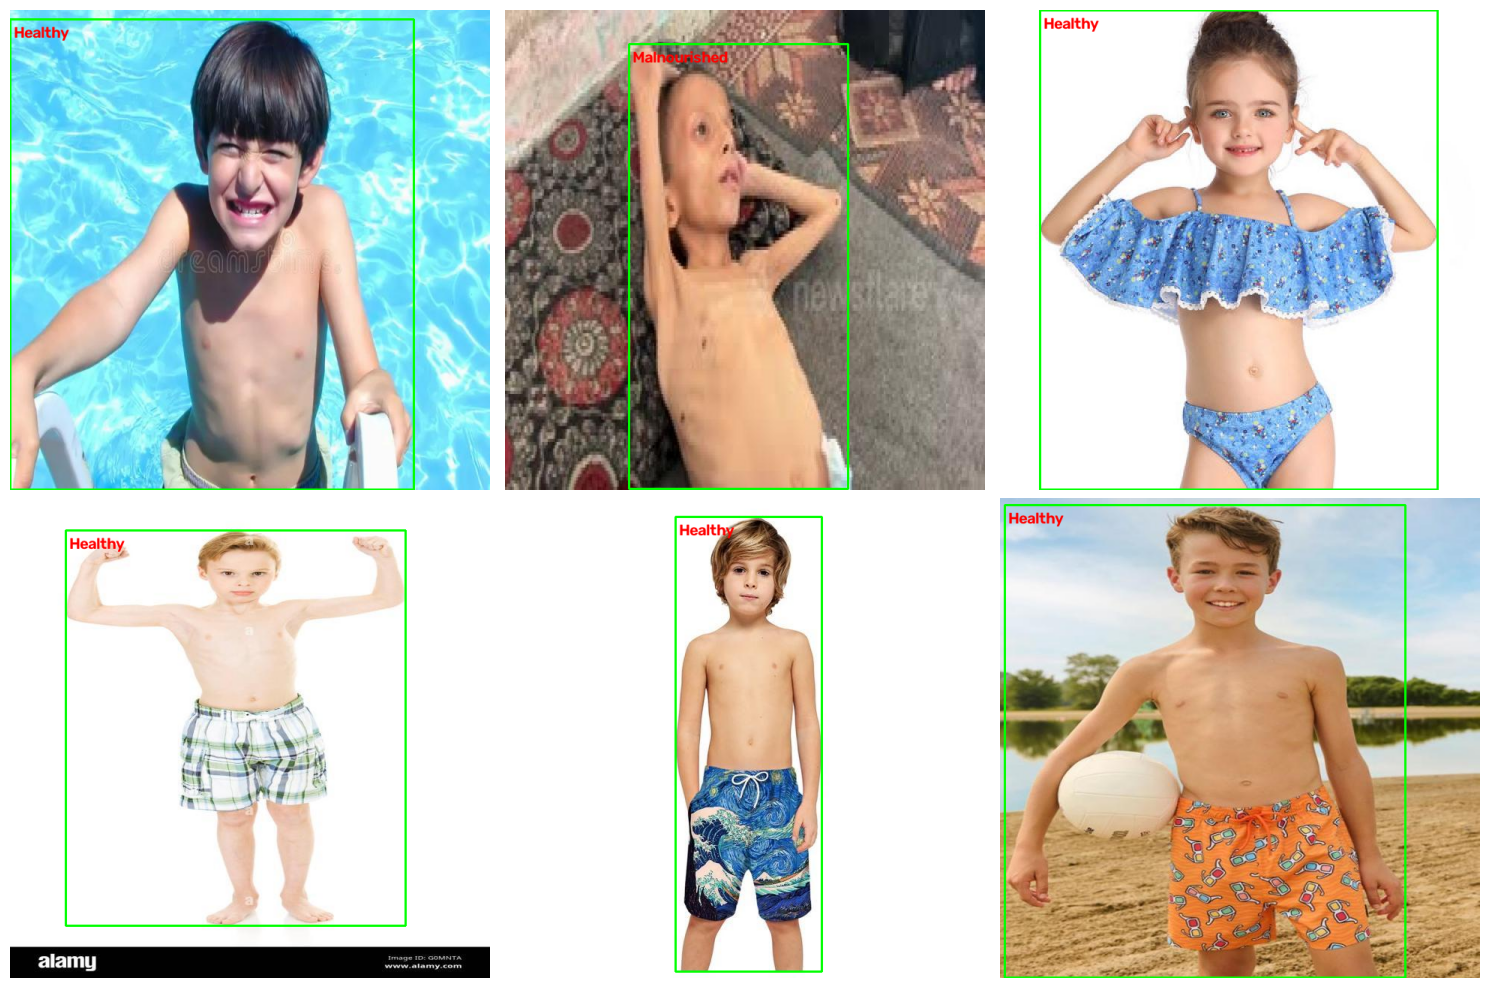

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/malnutrition_processed_v2"

class_names = {
    0: "Healthy",
    1: "Malnourished"
}

split = "train"

image_folder = os.path.join(dataset_path, split, "images")
label_folder = os.path.join(dataset_path, split, "labels")

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = random.sample(image_files, 6)

plt.figure(figsize=(15, 10))

for i, image_file in enumerate(sample_images):

    image_path = os.path.join(image_folder, image_file)

    label_file = os.path.splitext(image_file)[0] + ".txt"
    label_path = os.path.join(label_folder, label_file)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w, _ = image.shape

    if os.path.exists(label_path):

        with open(label_path, "r") as f:

            for line in f:

                values = line.strip().split()

                if len(values) < 5:
                    continue

                class_id = int(values[0])

                x_center = float(values[1]) * w
                y_center = float(values[2]) * h
                box_width = float(values[3]) * w
                box_height = float(values[4]) * h

                x1 = int(x_center - box_width / 2)
                y1 = int(y_center - box_height / 2)
                x2 = int(x_center + box_width / 2)
                y2 = int(y_center + box_height / 2)

                # Keep box inside image
                x1 = max(0, x1)
                y1 = max(0, y1)
                x2 = min(w - 1, x2)
                y2 = min(h - 1, y2)

                # Draw bounding box
                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                # Class name
                label = class_names.get(class_id, "Unknown")

                # Put label inside the image
                text_y = max(y1 + 25, 25)

                cv2.putText(
                    image,
                    label,
                    (x1 + 5, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 0, 0),
                    2
                )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Data Augmentation

In [ ]:
!pip install -q albumentations

In [ ]:
import os
import cv2
import albumentations as A

dataset_path = "/content/malnutrition_processed_v2"

image_folder = os.path.join(dataset_path, "train", "images")
label_folder = os.path.join(dataset_path, "train", "labels")

output_image_folder = os.path.join(dataset_path, "train_augmented", "images")
output_label_folder = os.path.join(dataset_path, "train_augmented", "labels")

os.makedirs(output_image_folder, exist_ok=True)
os.makedirs(output_label_folder, exist_ok=True)

transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=10, p=0.5),
        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        ),
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"]
    )
)

print("Augmentation setup completed.")

Augmentation setup completed.


In [ ]:
import os
import cv2
import albumentations as A

dataset_path = "/content/malnutrition_processed_v2"

image_folder = os.path.join(dataset_path, "train", "images")
label_folder = os.path.join(dataset_path, "train", "labels")

output_image_folder = os.path.join(
    dataset_path, "train_augmented", "images"
)

output_label_folder = os.path.join(
    dataset_path, "train_augmented", "labels"
)

os.makedirs(output_image_folder, exist_ok=True)
os.makedirs(output_label_folder, exist_ok=True)

transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=10, p=0.5),
        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        ),
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"]
    )
)

count = 0

for image_file in os.listdir(image_folder):

    if not image_file.lower().endswith(
        (".jpg", ".jpeg", ".png")
    ):
        continue

    image_path = os.path.join(image_folder, image_file)

    label_file = os.path.splitext(image_file)[0] + ".txt"
    label_path = os.path.join(label_folder, label_file)

    if not os.path.exists(label_path):
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    bboxes = []
    class_labels = []

    with open(label_path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) < 5:
                continue

            class_id = int(values[0])

            bbox = [
                float(values[1]),
                float(values[2]),
                float(values[3]),
                float(values[4])
            ]

            bboxes.append(bbox)
            class_labels.append(class_id)

    # Create one augmented version
    augmented = transform(
        image=image,
        bboxes=bboxes,
        class_labels=class_labels
    )

    augmented_image = augmented["image"]
    augmented_bboxes = augmented["bboxes"]
    augmented_classes = augmented["class_labels"]

    # Convert RGB back to BGR for saving
    augmented_image = cv2.cvtColor(
        augmented_image,
        cv2.COLOR_RGB2BGR
    )

    # Save augmented image
    output_name = (
        os.path.splitext(image_file)[0]
        + "_aug.jpg"
    )

    cv2.imwrite(
        os.path.join(output_image_folder, output_name),
        augmented_image
    )

    # Save corresponding YOLO label
    output_label_name = (
        os.path.splitext(image_file)[0]
        + "_aug.txt"
    )

    with open(
        os.path.join(output_label_folder, output_label_name),
        "w"
    ) as f:

        for class_id, bbox in zip(
            augmented_classes,
            augmented_bboxes
        ):

            f.write(
                f"{class_id} "
                f"{bbox[0]:.6f} "
                f"{bbox[1]:.6f} "
                f"{bbox[2]:.6f} "
                f"{bbox[3]:.6f}\n"
            )

    count += 1

print("Augmentation completed!")
print("Augmented images created:", count)

Augmentation completed!
Augmented images created: 118


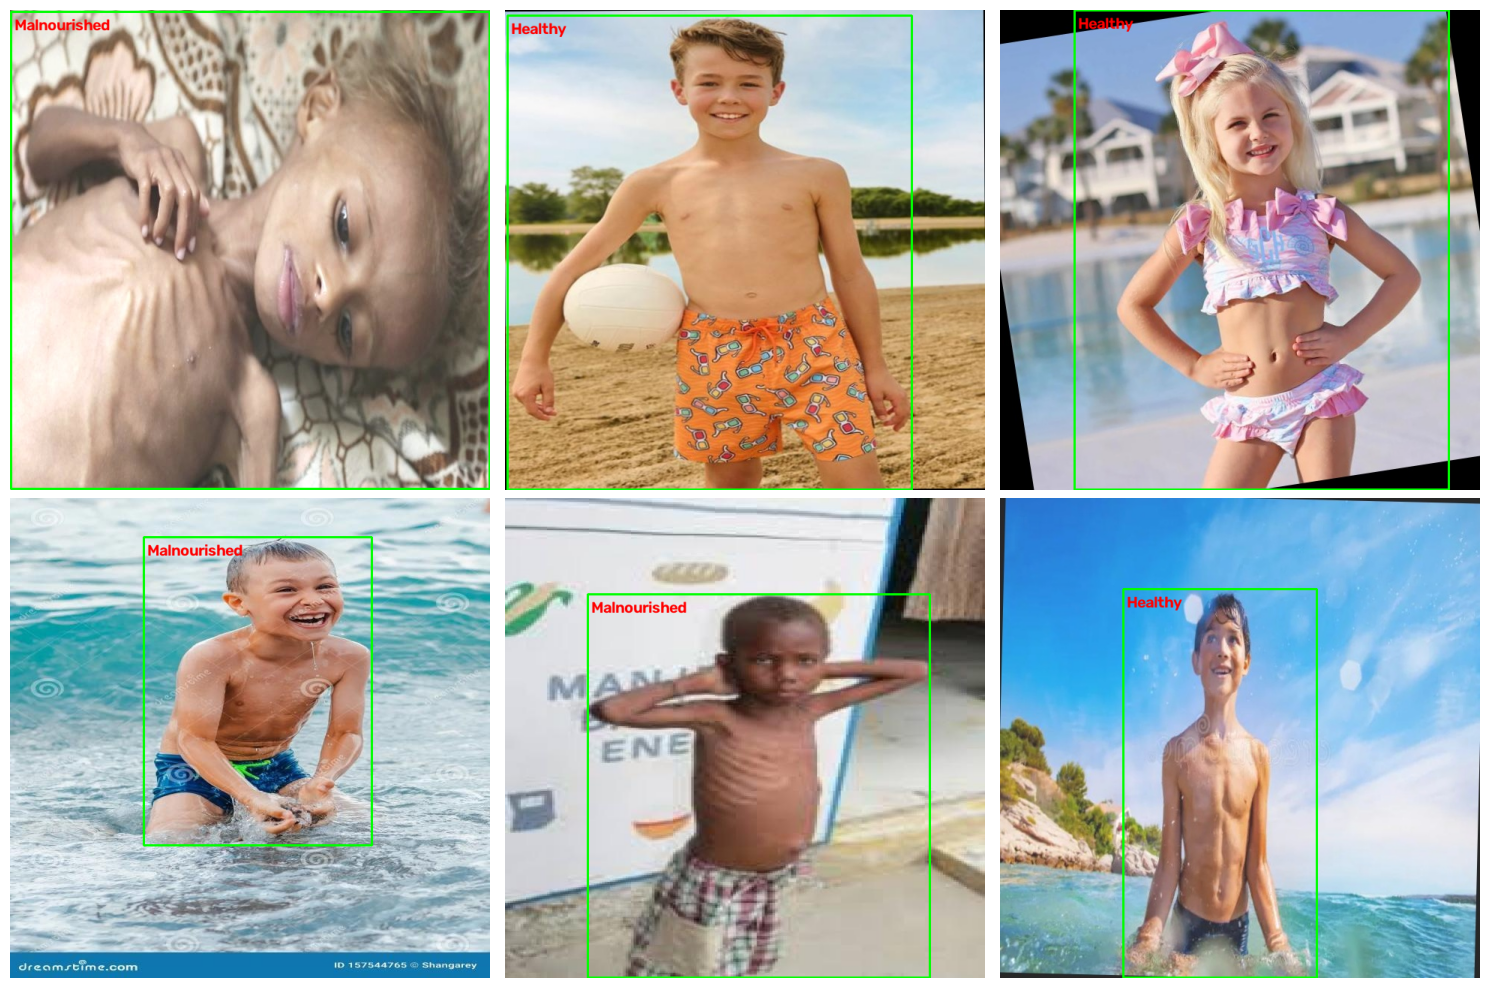

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

image_folder = "/content/malnutrition_processed_v2/train_augmented/images"
label_folder = "/content/malnutrition_processed_v2/train_augmented/labels"

class_names = {
    0: "Healthy",
    1: "Malnourished"
}

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = random.sample(
    image_files,
    min(6, len(image_files))
)

plt.figure(figsize=(15, 10))

for i, image_file in enumerate(sample_images):

    image_path = os.path.join(image_folder, image_file)
    label_file = os.path.splitext(image_file)[0] + ".txt"
    label_path = os.path.join(label_folder, label_file)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w, _ = image.shape

    if os.path.exists(label_path):

        with open(label_path, "r") as f:

            for line in f:

                values = line.strip().split()

                if len(values) < 5:
                    continue

                class_id = int(float(values[0]))

                x_center = float(values[1]) * w
                y_center = float(values[2]) * h
                box_width = float(values[3]) * w
                box_height = float(values[4]) * h

                x1 = int(x_center - box_width / 2)
                y1 = int(y_center - box_height / 2)
                x2 = int(x_center + box_width / 2)
                y2 = int(y_center + box_height / 2)

                x1 = max(0, x1)
                y1 = max(0, y1)
                x2 = min(w - 1, x2)
                y2 = min(h - 1, y2)

                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                label = class_names.get(
                    class_id,
                    "Unknown"
                )

                cv2.putText(
                    image,
                    label,
                    (x1 + 5, max(y1 + 25, 25)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 0, 0),
                    2
                )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Create the Final Training Dataset

In [ ]:
import os
import shutil

base_path = "/content/malnutrition_processed_v2"

final_path = "/content/malnutrition_final"

for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(final_path, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(final_path, split, "labels"), exist_ok=True)


# Copy original training data
for folder in ["images", "labels"]:

    source = os.path.join(base_path, "train", folder)
    destination = os.path.join(final_path, "train", folder)

    for file in os.listdir(source):
        shutil.copy2(
            os.path.join(source, file),
            os.path.join(destination, file)
        )


# Copy augmented training data
for folder in ["images", "labels"]:

    source = os.path.join(
        base_path,
        "train_augmented",
        folder
    )

    destination = os.path.join(
        final_path,
        "train",
        folder
    )

    for file in os.listdir(source):
        shutil.copy2(
            os.path.join(source, file),
            os.path.join(destination, file)
        )


# Copy validation and test data
for split in ["valid", "test"]:

    for folder in ["images", "labels"]:

        source = os.path.join(
            base_path,
            split,
            folder
        )

        destination = os.path.join(
            final_path,
            split,
            folder
        )

        for file in os.listdir(source):
            shutil.copy2(
                os.path.join(source, file),
                os.path.join(destination, file)
            )


print("Final dataset created successfully!")
print(final_path)

Final dataset created successfully!
/content/malnutrition_final


In [ ]:
import yaml

data = {
    "path": "/content/malnutrition_final",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": ["Healthy", "Malnourished"]
}

yaml_path = "/content/malnutrition_final/data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("data.yaml created successfully!")
print(yaml_path)

data.yaml created successfully!
/content/malnutrition_final/data.yaml


## Final Dataset Count

In [ ]:
import os

final_path = "/content/malnutrition_final"

for split in ["train", "valid", "test"]:

    image_path = os.path.join(final_path, split, "images")
    label_path = os.path.join(final_path, split, "labels")

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_path)
        if f.lower().endswith(".txt")
    ]

    print("=" * 40)
    print(split.upper())
    print("Images :", len(images))
    print("Labels :", len(labels))

TRAIN
Images : 236
Labels : 236
VALID
Images : 48
Labels : 48
TEST
Images : 38
Labels : 38


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copytree(
    "/content/malnutrition_final",
    "/content/drive/MyDrive/malnutrition_final",
    dirs_exist_ok=True
)

print("Final dataset copied to Google Drive successfully!")

Final dataset copied to Google Drive successfully!
